---
# 0. Librerías y configuración global

Se fija la **semilla aleatoria** (`SEED = 42`) para que todos los resultados sean reproducibles. Los archivos CSV deben estar en la misma carpeta que este cuaderno (o se modifica `DATA_DIR`).

In [21]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.utils.class_weight import compute_sample_weight
from scipy.stats import loguniform, randint

warnings.filterwarnings('ignore')

SEED     = 42            # semilla global (reproducibilidad)
DATA_DIR = '.'           # carpeta donde están los CSV
FIG_DIR  = 'figuras'     # carpeta de salida de las figuras
os.makedirs(FIG_DIR, exist_ok=True)
np.random.seed(SEED)

import sklearn
print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.4.6


### Estilo gráfico académico y código de diferenciación

Para que los tres modelos se distingan **incluso en una impresión en blanco y negro**, cada uno tiene un color, un tipo de línea, un marcador y un patrón de relleno propios:

| Modelo | Color | Línea | Marcador | Relleno de barras |
|---|---|---|---|---|
| Regresión logística | azul | continua | círculo | liso |
| Random Forest | verde | discontinua | cuadrado | rayas `//` |
| Gradient Boosting | rojo | punto-raya | triángulo | cruces `xx` |

In [22]:
plt.rcParams.update({
    'font.family': 'serif', 'font.serif': ['DejaVu Serif', 'Times New Roman'],
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.30, 'grid.linestyle': '--',
    'legend.frameon': False, 'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

ORDEN = ['Regresión logística', 'Random Forest', 'Gradient Boosting']
COL   = {'Regresión logística': '#1f4e9c', 'Random Forest': '#2a8c4a', 'Gradient Boosting': '#c0392b'}
LS    = {'Regresión logística': '-',       'Random Forest': '--',      'Gradient Boosting': '-.'}
MK    = {'Regresión logística': 'o',       'Random Forest': 's',       'Gradient Boosting': '^'}
HATCH = {'Regresión logística': '',        'Random Forest': '//',      'Gradient Boosting': 'xx'}
CMAP  = {'Regresión logística': 'Blues',   'Random Forest': 'Greens',  'Gradient Boosting': 'Reds'}
DS_NOMBRE = {'A': 'Tabla A (bank_full_modelo)'}

def guardar(fig, nombre):
    fig.savefig(f'{FIG_DIR}/{nombre}.png')
    plt.show()

---
# 1. c.1 — Preparación final de los datos

## 1.1 Carga de la tabla minable

In [23]:
from pathlib import Path

TABLA_DIR = Path("tabla_minable")

modelo = pd.read_csv(TABLA_DIR / "bank_full_modelo.csv")
print(f'Tabla A (bank_full_modelo)    : {modelo.shape[0]:,} filas x {modelo.shape[1]} columnas')

display(modelo.head(3))

Tabla A (bank_full_modelo)    : 45,208 filas x 43 columnas


,age,day,balance_log,campaign_cap,previous_cap,default_bin,housing_bin,loan_bin,balance_negativo,job_imputada,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown,yb
0,58,5,7.670429,1,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
1,44,5,3.401197,1,0,0,1,0,0,0,...,0,0,1,0,0,0,0,0,1,0
2,33,5,1.098612,1,0,0,1,1,0,0,...,0,0,1,0,0,0,0,0,1,0


## 1.2 Verificación de calidad y consistencia entre las tablas

Antes de modelar se comprueba que (i) la variable objetivo `yb` existe y es binaria (0/1), (ii) todas las columnas predictoras son numéricas y (iii) no hay valores faltantes que impidan entrenar.

In [24]:
# (i)-(ii) Verificación de la variable objetivo y del tipo de las columnas en la Tabla A
assert 'yb' in modelo.columns, "Falta la columna objetivo 'yb'"
assert set(modelo['yb'].unique()) <= {0, 1}, "'yb' debe ser binaria (0/1)"
assert all(np.issubdtype(t, np.number) for t in modelo.dtypes), 'Hay columnas no numéricas en la Tabla A'
print('OK: tabla verificada correctamente.\n')

# (iii) Calidad de la Tabla A
calidad = pd.DataFrame({
    'Filas':               [len(modelo)],
    'Columnas':            [modelo.shape[1]],
    'Valores nulos':       [int(modelo.isna().sum().sum())],
    'Columnas con nulos':  [int((modelo.isna().sum() > 0).sum())],
    'Filas duplicadas':    [int(modelo.duplicated().sum())],
}, index=['Tabla A'])
display(calidad)

print('Columnas con nulos en la Tabla A:')
display(modelo.isna().sum()[modelo.isna().sum() > 0].to_frame('nulos'))

OK: tabla verificada correctamente.



,Filas,Columnas,Valores nulos,Columnas con nulos,Filas duplicadas
Tabla A,45208,43,0,0,20


Columnas con nulos en la Tabla A:


,nulos


## 1.3 Análisis exploratorio mínimo de la variable objetivo

El desbalance de clases condiciona **toda** la estrategia de modelado (métricas, pesos de clase, umbral de decisión), por eso se cuantifica primero.

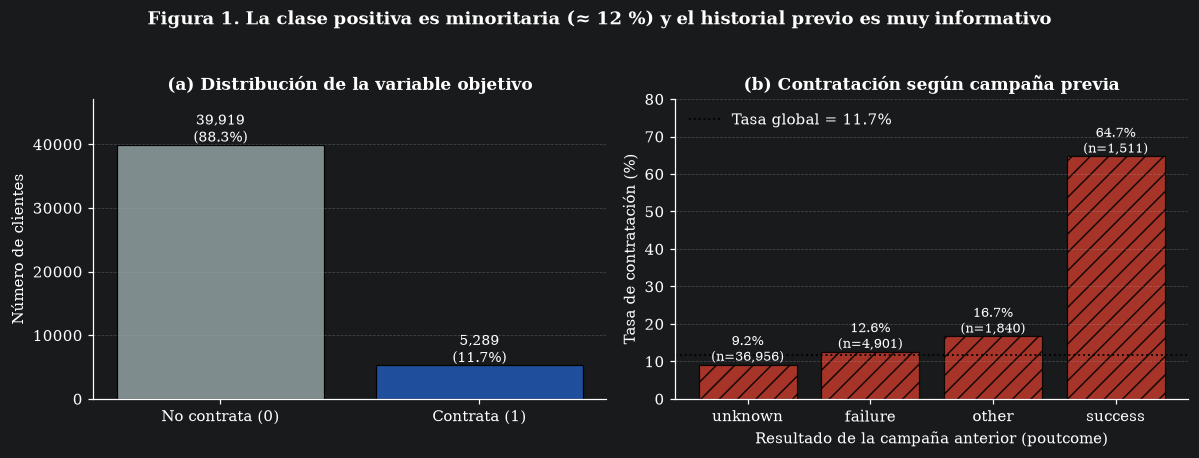

Razón de desbalance (negativos : positivos) = 7.55 : 1


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# (a) Distribución de la variable objetivo
cuentas = modelo['yb'].value_counts().reindex([0, 1])
barras = ax[0].bar(['No contrata (0)', 'Contrata (1)'], cuentas.values, color=['#7f8c8d', '#1f4e9c'],
                   edgecolor='black', linewidth=0.8)
for b, v in zip(barras, cuentas.values):
    ax[0].text(b.get_x() + b.get_width()/2, v + 500, f'{v:,}\n({v/len(modelo):.1%})', ha='center', fontsize=9)
ax[0].set_ylabel('Número de clientes'); ax[0].set_ylim(0, cuentas.max()*1.18)
ax[0].set_title('(a) Distribución de la variable objetivo')
ax[0].grid(axis='x', visible=False)

# (b) Tasa de contratación según el resultado de la campaña anterior (poutcome)
# bank_full_modelo codifica poutcome con dummies; 'failure' es la categoría de referencia (sin columna)
orden_p = ['unknown', 'failure', 'other', 'success']
grupo_p = np.select([modelo['poutcome_success'] == 1, modelo['poutcome_other'] == 1, modelo['poutcome_unknown'] == 1],
                    ['success', 'other', 'unknown'], default='failure')
tasa_p = modelo.groupby(grupo_p)['yb'].agg(['mean', 'count']).reindex(orden_p)
b2 = ax[1].bar(orden_p, tasa_p['mean']*100, color='#c0392b', edgecolor='black', linewidth=0.8, hatch='//', alpha=0.85)
for b, (m_, n_) in zip(b2, tasa_p.itertuples(index=False)):
    ax[1].text(b.get_x() + b.get_width()/2, m_*100 + 1, f'{m_:.1%}\n(n={n_:,})', ha='center', fontsize=8.5)
ax[1].axhline(modelo['yb'].mean()*100, color='black', ls=':', lw=1.2, label=f"Tasa global = {modelo['yb'].mean():.1%}")
ax[1].set_ylabel('Tasa de contratación (%)'); ax[1].set_ylim(0, 80)
ax[1].set_xlabel('Resultado de la campaña anterior (poutcome)')
ax[1].set_title('(b) Contratación según campaña previa'); ax[1].legend(loc='upper left')
ax[1].grid(axis='x', visible=False)

fig.suptitle('Figura 1. La clase positiva es minoritaria (≈ 12 %) y el historial previo es muy informativo', y=1.03, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig01_distribucion_objetivo')
print(f"Razón de desbalance (negativos : positivos) = {cuentas.loc[0]/cuentas.loc[1]:.2f} : 1")

## 1.4 Construcción de la matriz de características final

### Tabla A — `bank_full_modelo.csv`
Ya está lista para modelar: todas las columnas son numéricas y no hay nulos. Se separa la variable objetivo `yb` (**y**) del resto (**X**). Las seis variables continuas se estandarizarán únicamente dentro del pipeline de la regresión logística; las dummies (0/1) se dejan sin tocar.

In [26]:
y = modelo['yb'].astype(int)

# ---------- Tabla A ----------
X_A = modelo.drop(columns='yb').copy()
cont_A = ['age', 'day', 'balance_log', 'campaign_cap', 'previous_cap', 'dias_desde_contacto_previo']
bin_A  = [c for c in X_A.columns if c not in cont_A]
cat_A  = []

print(f'Tabla A -> X: {X_A.shape} | continuas: {len(cont_A)} | binarias (dummies): {len(bin_A)}')
assert X_A.isna().sum().sum() == 0 and all(np.issubdtype(t, np.number) for t in X_A.dtypes)

Tabla A -> X: (45208, 42) | continuas: 6 | binarias (dummies): 36


## 1.5 División en conjuntos de entrenamiento y prueba

Se separa el **80 % para entrenar** y el **20 % para probar**. Decisiones y justificación:

| Parámetro de `train_test_split` | Valor | Justificación |
|---|---|---|
| `test_size` | `0.20` | Regla estándar 80/20: 36 166 clientes para aprender y 9 042 para una evaluación estable (≈ 1 058 positivos en prueba). |
| `stratify` | `y` | **Estratificación**: conserva la proporción de clases (≈ 11,7 % de positivos) en ambos conjuntos. Imprescindible con clases desbalanceadas. |
| `random_state` | `42` | Reproducibilidad. |
| `shuffle` | `True` (por defecto) | Rompe el orden cronológico del archivo. |

> **Detalle importante:** la partición se hace **una sola vez sobre los índices** y se aplica a la Tabla A. Así, los tres algoritmos se entrenan y se evalúan sobre **exactamente los mismos clientes**, y la comparación entre modelos es justa.

El conjunto de prueba **no se toca** hasta la evaluación final: el ajuste de hiperparámetros y del umbral se hace solo con validación cruzada sobre el conjunto de entrenamiento.

,Clientes,Positivos,% positivos
Total,45208,5289,11.7
Entrenamiento (80 %),36166,4231,11.7
Prueba (20 %),9042,1058,11.7


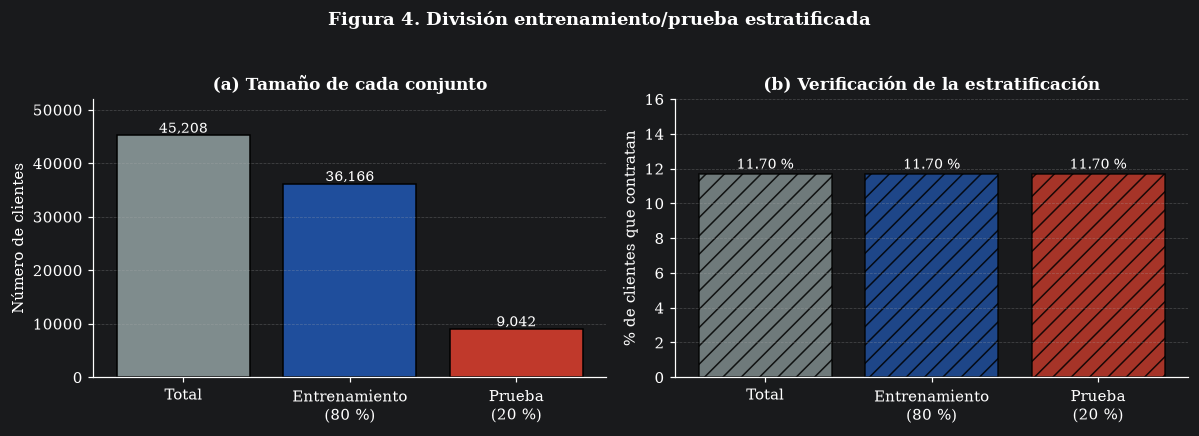

Los tres modelos se entrenan con 36166 clientes y se evalúan con 9042 clientes de prueba.


In [27]:
idx = np.arange(len(y))
idx_tr, idx_te = train_test_split(idx, test_size=0.20, stratify=y, random_state=SEED)

DATOS = {
    'A': dict(X_tr=X_A.iloc[idx_tr], X_te=X_A.iloc[idx_te]),
}
for k in DATOS:
    DATOS[k]['y_tr'] = y.iloc[idx_tr]
    DATOS[k]['y_te'] = y.iloc[idx_te]

y_tr, y_te = DATOS['A']['y_tr'], DATOS['A']['y_te']
resumen_split = pd.DataFrame({
    'Clientes':   [len(y), len(y_tr), len(y_te)],
    'Positivos':  [int(y.sum()), int(y_tr.sum()), int(y_te.sum())],
    '% positivos': [y.mean()*100, y_tr.mean()*100, y_te.mean()*100],
}, index=['Total', 'Entrenamiento (80 %)', 'Prueba (20 %)'])
display(resumen_split.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
nombres = ['Total', 'Entrenamiento\n(80 %)', 'Prueba\n(20 %)']
bs = ax[0].bar(nombres, resumen_split['Clientes'], color=['#7f8c8d', '#1f4e9c', '#c0392b'], edgecolor='black')
for b_, v in zip(bs, resumen_split['Clientes']):
    ax[0].text(b_.get_x()+b_.get_width()/2, v+500, f'{v:,}', ha='center', fontsize=9)
ax[0].set_ylabel('Número de clientes'); ax[0].set_title('(a) Tamaño de cada conjunto'); ax[0].set_ylim(0, 52000)
ax[0].grid(axis='x', visible=False)

bs = ax[1].bar(nombres, resumen_split['% positivos'], color=['#7f8c8d', '#1f4e9c', '#c0392b'], edgecolor='black', hatch='//', alpha=0.85)
for b_, v in zip(bs, resumen_split['% positivos']):
    ax[1].text(b_.get_x()+b_.get_width()/2, v+0.3, f'{v:.2f} %', ha='center', fontsize=9)
ax[1].set_ylabel('% de clientes que contratan'); ax[1].set_ylim(0, 16)
ax[1].set_title('(b) Verificación de la estratificación'); ax[1].grid(axis='x', visible=False)
fig.suptitle('Figura 4. División entrenamiento/prueba estratificada', y=1.03, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig04_division_train_test')

assert len(DATOS['A']['X_tr']) == len(y_tr) and len(DATOS['A']['X_te']) == len(y_te)
assert set(idx_tr).isdisjoint(idx_te)      # ningún cliente está a la vez en entrenamiento y prueba
print('Los tres modelos se entrenan con', len(y_tr), 'clientes y se evalúan con', len(y_te), 'clientes de prueba.')

---
# 2. c.2 — Selección de los algoritmos

**Tipo de problema → algoritmo.** Como la variable objetivo es binaria (contrata / no contrata), se trata de **clasificación supervisada**. Se proponen **tres modelos** de familias distintas y, además, cada uno se entrena en **dos versiones** (línea base y versión con hiperparámetros optimizados), de modo que la comparación incluye el efecto del ajuste de parámetros.

| Modelo | Familia | Por qué se elige |
|---|---|---|
| **Regresión logística** | Lineal, paramétrico | Línea base interpretable (coeficientes → *odds ratios*). |
| **Random Forest** | Ensamble por *bagging* de árboles | Captura no linealidades e interacciones; robusto al ruido; poca sensibilidad a la escala. |
| **Gradient Boosting** | Ensamble por *boosting* de árboles | Suele dar el mejor desempeño en datos tabulares; corrige secuencialmente los errores del modelo previo. |

## 2.1 Regresión logística

Modela la probabilidad de contratar como una función sigmoide de una combinación lineal de las variables:

$$P(y=1\mid \mathbf{x}) = \sigma(z)=\frac{1}{1+e^{-z}},\qquad z=\beta_0+\sum_{j=1}^{p}\beta_j x_j$$

Los coeficientes se estiman minimizando la **pérdida logarítmica con regularización L2**:

$$\min_{\boldsymbol\beta}\ \ \tfrac12\lVert\boldsymbol\beta\rVert_2^2 \;+\; C\sum_{i=1}^{n} w_i\,\log\!\big(1+e^{-\tilde y_i z_i}\big)$$

| Parámetro | Valor usado | Explicación |
|---|---|---|
| `C` | línea base `1.0`; búsqueda `loguniform(1e-3, 1e2)` | **Inverso de la fuerza de regularización**. `C` pequeño → coeficientes más encogidos (modelo más simple, menos sobreajuste); `C` grande → ajuste más libre. Se explora en escala logarítmica porque su efecto es multiplicativo. |
| `penalty` / regularización | L2 (por defecto) | Penaliza la suma de cuadrados de los coeficientes; estabiliza la estimación con variables correlacionadas (p. ej. las dummies de mes). |
| `solver` | `lbfgs` (por defecto) | Optimizador cuasi-Newton, adecuado para L2 y datos de tamaño medio. |
| `max_iter` | `2000` | Máximo de iteraciones; se sube desde 100 para garantizar convergencia. |
| `class_weight` | `'balanced'` | Pesa cada clase con $w_c = n/(2\,n_c)$: cada positivo recibe ≈ 4,27 y cada negativo ≈ 0,57, es decir, un positivo pesa ≈ 7,5 veces más que un negativo. Evita que el modelo ignore la clase minoritaria. |
| `random_state` | `42` | Reproducibilidad. |
| *Preprocesamiento* | `StandardScaler` en las variables continuas | La regularización y el optimizador son sensibles a la escala; sin estandarizar, `C` penalizaría de forma desigual a cada variable. |

## 2.2 Random Forest

Entrena $B$ árboles de decisión sobre **muestras bootstrap** de los datos y, en cada división, solo considera un **subconjunto aleatorio de variables**. Al promediar árboles poco correlacionados se reduce la varianza sin aumentar mucho el sesgo:

$$\hat P(y=1\mid\mathbf x)=\frac1B\sum_{b=1}^{B} T_b(\mathbf x)$$

Cada árbol elige sus cortes minimizando la **impureza de Gini**, $G=1-\sum_k p_k^2$.

| Parámetro | Valor línea base → espacio de búsqueda | Explicación |
|---|---|---|
| `n_estimators` | `200` → entero en [150, 400] | Número de árboles $B$. Más árboles reducen la varianza, con rendimientos decrecientes. |
| `max_depth` | `10` → {6, 8, 10, 12, 16, None} | Profundidad máxima. Controla la complejidad: árboles muy profundos memorizan el ruido. |
| `min_samples_leaf` | `5` → {1, 3, 5, 10, 20} | Mínimo de observaciones por hoja. Valores altos suavizan las predicciones (regularización). |
| `max_features` | `'sqrt'` → {'sqrt', 0.3, 0.5} | Variables evaluadas en cada corte. Menos variables → árboles más diversos y menos correlacionados. |
| `class_weight` | `'balanced_subsample'` → {'balanced', 'balanced_subsample'} | Reponderación de clases (la segunda recalcula los pesos en cada muestra bootstrap). |
| `bootstrap` | `True` (por defecto) | Muestreo con reemplazo de las filas de cada árbol. |
| `criterion` | `'gini'` (por defecto) | Medida de impureza. |
| `random_state` | `42` | Reproducibilidad. |

## 2.3 Gradient Boosting

Construye un modelo **aditivo y secuencial**: cada árbol pequeño $h_m$ se ajusta al **gradiente negativo de la pérdida** (en clasificación con `log_loss`, los residuos $r_i=y_i-\hat p_i$) del modelo acumulado, y se suma con un factor de aprendizaje $\nu$:

$$F_m(\mathbf x)=F_{m-1}(\mathbf x)+\nu\, h_m(\mathbf x),\qquad \hat P(y=1\mid\mathbf x)=\sigma\big(F_M(\mathbf x)\big)$$

| Parámetro | Valor línea base → espacio de búsqueda | Explicación |
|---|---|---|
| `n_estimators` | `300` → {200, 300, 400} | Número **máximo** de árboles $M$. Con parada temprana (ver abajo) el número real suele ser menor. |
| `learning_rate` ($\nu$) | `0.1` → `loguniform(0.02, 0.2)` | Contribución de cada árbol. Valores pequeños = aprendizaje más lento pero más preciso (requieren más árboles). Es el parámetro más influyente junto con `n_estimators`. |
| `max_depth` | `3` → {2, 3, 4, 5} | Profundidad de los árboles base. En *boosting* se usan árboles **débiles** (poco profundos) para evitar el sobreajuste. |
| `subsample` | `0.8` → {0.6, …, 1.0} | Fracción de filas usada por árbol (*Stochastic Gradient Boosting*). Valores < 1 reducen la varianza. |
| `min_samples_leaf` | `20` → {10, 20, 50, 100} | Mínimo de observaciones por hoja (regularización). |
| `max_features` | `None` → {None, 'sqrt', 0.5} | Variables consideradas en cada corte (aleatoriza y acelera). |
| `n_iter_no_change` | `10` | **Parada temprana**: se detiene si en 10 iteraciones consecutivas no mejora la pérdida en el conjunto de validación interno. |
| `validation_fraction` | `0.1` | 10 % de los datos de entrenamiento se reserva internamente para la parada temprana. |
| `loss` | `'log_loss'` (por defecto) | Pérdida logarítmica = verosimilitud binomial. |
| `sample_weight` | `'balanced'` | `GradientBoostingClassifier` no tiene `class_weight`; el equivalente es pasar pesos por muestra en `fit`. |
| `random_state` | `42` | Reproducibilidad. |

## 2.4 Diseño experimental

| Elemento | Decisión |
|---|---|
| Conjuntos | 80 % entrenamiento / 20 % prueba, estratificado (sección 1.5). |
| Tabla | A (`bank_full_modelo`): **3 modelos** en total (3 algoritmos), cada uno con su línea base y su versión optimizada. |
| Búsqueda de hiperparámetros | `RandomizedSearchCV` con **10 configuraciones aleatorias** por modelo (búsqueda aleatoria: más eficiente que una malla completa cuando hay varios hiperparámetros continuos). |
| Validación | Validación cruzada **estratificada de 3 particiones** (`StratifiedKFold`) **solo dentro del entrenamiento**. |
| Métrica de selección | **AUC-PR** (`average_precision`): es la más informativa con clases desbalanceadas porque se centra en la clase positiva. |
| Umbral de decisión | Se elige el umbral que maximiza **F1** sobre predicciones *out-of-fold* del entrenamiento (nunca sobre la prueba). |
| Evaluación final | Una sola vez sobre el 20 % de prueba. |

---
# 3. Entrenamiento de los modelos

## 3.1 Preprocesamiento por tabla y configuración de los modelos

El preprocesamiento va **dentro de un `Pipeline`** de scikit-learn. Esto evita la **fuga de información** del preprocesamiento: el escalador y el codificador se ajustan solo con los datos de cada partición de entrenamiento y nunca ven los datos de validación o de prueba.

In [28]:
# Grupos de columnas por tabla
GRUPOS = {
    'A': dict(cont=cont_A, bin=bin_A, cat=cat_A),
}

def crear_preprocesador(ds, escalar):
    # ColumnTransformer: estandariza las continuas (si escalar), deja pasar las binarias y codifica las categóricas.
    g = GRUPOS[ds]
    piezas = [('cont', StandardScaler() if escalar else 'passthrough', g['cont']),
              ('bin',  'passthrough', g['bin'])]
    if g['cat']:
        piezas.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), g['cat']))
    return ColumnTransformer(piezas, verbose_feature_names_out=False)

# Configuración de los tres algoritmos: línea base y espacio de búsqueda
CONFIG = {
    'Regresión logística': dict(
        clasificador=lambda **kw: LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED, **kw),
        escalar=True, pesos=False,
        base=dict(C=1.0),
        espacio={'clf__C': loguniform(1e-3, 1e2)},
        n_iter=10),
    'Random Forest': dict(
        clasificador=lambda **kw: RandomForestClassifier(random_state=SEED, n_jobs=1, **kw),
        escalar=False, pesos=False,
        base=dict(n_estimators=200, max_depth=10, min_samples_leaf=5, max_features='sqrt',
                  class_weight='balanced_subsample'),
        espacio={'clf__n_estimators': randint(150, 401),
                 'clf__max_depth': [6, 8, 10, 12, 16, None],
                 'clf__min_samples_leaf': [1, 3, 5, 10, 20],
                 'clf__max_features': ['sqrt', 0.3, 0.5],
                 'clf__class_weight': ['balanced', 'balanced_subsample']},
        n_iter=10),
    'Gradient Boosting': dict(
        clasificador=lambda **kw: GradientBoostingClassifier(n_iter_no_change=10, validation_fraction=0.1,
                                                              tol=1e-4, random_state=SEED, **kw),
        escalar=False, pesos=True,
        base=dict(n_estimators=300, learning_rate=0.1, max_depth=3, subsample=0.8, min_samples_leaf=20),
        espacio={'clf__n_estimators': [200, 300, 400],
                 'clf__learning_rate': loguniform(0.02, 0.2),
                 'clf__max_depth': [2, 3, 4, 5],
                 'clf__subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
                 'clf__min_samples_leaf': [10, 20, 50, 100],
                 'clf__max_features': [None, 'sqrt', 0.5]},
        n_iter=10),
}

CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
print('Configuración cargada para:', list(CONFIG))

Configuración cargada para: ['Regresión logística', 'Random Forest', 'Gradient Boosting']


## 3.2 Funciones de entrenamiento y optimización de hiperparámetros

`entrenar_modelo(tabla, algoritmo)` ejecuta el procedimiento de ajuste estrictamente sobre el conjunto de entrenamiento:

1. **Línea base:** ajusta el pipeline con los hiperparámetros por defecto de la sección 2 sobre `X_tr`.
2. **Búsqueda aleatoria** de hiperparámetros (`RandomizedSearchCV`) con validación cruzada estratificada de 3 particiones (métrica: AUC-PR) sobre `X_tr` y reajuste del mejor estimador sobre todo el conjunto de entrenamiento.
3. **Umbral óptimo** de F1 obtenido con predicciones *out-of-fold* de validación cruzada sobre el entrenamiento (para evitar fuga de información).

> **Principio de evaluación:** El conjunto de prueba (`X_te`, `y_te`) permanece estrictamente ciego durante esta sección y se evaluará únicamente en la **Sección 4**.

In [29]:
def metricas(y_real, proba, umbral):
    # Métricas independientes del umbral (AUC) y dependientes del umbral (resto)
    pred = (proba >= umbral).astype(int)
    return {'AUC_ROC': roc_auc_score(y_real, proba), 'AUC_PR': average_precision_score(y_real, proba),
            'Accuracy': accuracy_score(y_real, pred), 'Bal_Acc': balanced_accuracy_score(y_real, pred),
            'Precision': precision_score(y_real, pred, zero_division=0), 'Recall': recall_score(y_real, pred),
            'F1': f1_score(y_real, pred), 'MCC': matthews_corrcoef(y_real, pred), 'Umbral': umbral}

def umbral_f1(y_real, proba):
    # Umbral que maximiza F1 sobre las probabilidades out-of-fold de entrenamiento
    p, r, t = precision_recall_curve(y_real, proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])

RES = {'A': {}}      # almacén de modelos y resultados de entrenamiento

def entrenar_modelo(ds, nombre):
    cfg, d = CONFIG[nombre], DATOS[ds]
    X_tr, y_tr_ = d['X_tr'], d['y_tr']
    fp = {'clf__sample_weight': compute_sample_weight('balanced', y_tr_)} if cfg['pesos'] else {}
    t0 = time.time()

    # (1) Línea base: ajuste sobre entrenamiento
    pipe_base = Pipeline([('prep', crear_preprocesador(ds, cfg['escalar'])), ('clf', cfg['clasificador'](**cfg['base']))])
    pipe_base.fit(X_tr, y_tr_, **fp)

    # (2) Búsqueda aleatoria de hiperparámetros con CV estratificada sobre entrenamiento
    pipe = Pipeline([('prep', crear_preprocesador(ds, cfg['escalar'])), ('clf', cfg['clasificador']())])
    busq = RandomizedSearchCV(pipe, cfg['espacio'], n_iter=cfg['n_iter'], scoring='average_precision', cv=CV,
                              n_jobs=-1, random_state=SEED, refit=True, return_train_score=True)
    busq.fit(X_tr, y_tr_, **fp)
    mejor = busq.best_estimator_

    # (3) Umbral óptimo de F1 con predicciones out-of-fold del entrenamiento (sin fuga)
    oof = cross_val_predict(clone(mejor), X_tr, y_tr_, cv=CV, method='predict_proba', params=fp, n_jobs=-1)[:, 1]
    umbral = umbral_f1(y_tr_, oof)

    RES[ds][nombre] = dict(
        pipe=mejor, pipe_base=pipe_base, cv=pd.DataFrame(busq.cv_results_), mejores=busq.best_params_,
        cv_score=busq.best_score_, umbral=umbral, segundos=time.time() - t0)

    r = RES[ds][nombre]
    print(f'{nombre} | bank_full_modelo.csv  ({r["segundos"]:.0f} s)')
    print('  Mejores hiperparámetros :', {k.replace('clf__', ''): (round(float(v), 4) if isinstance(v, (float, np.floating)) else v)
                                           for k, v in r['mejores'].items()})
    if nombre == 'Gradient Boosting':
        print('  Árboles usados tras parada temprana:', r['pipe'].named_steps['clf'].n_estimators_)
    print(f'  AUC-PR en validación cruzada (CV) = {r["cv_score"]:.4f}')
    print(f'  Umbral óptimo calibrado en train (OOF) = {r["umbral"]:.3f}')


## 3.3 Entrenamiento sobre `bank_full_modelo.csv`

### Modelo 1 — Regresión logística

In [30]:
entrenar_modelo('A', 'Regresión logística')

Regresión logística | bank_full_modelo.csv  (7 s)
  Mejores hiperparámetros : {'C': 0.0746}
  AUC-PR en validación cruzada (CV) = 0.4016
  Umbral óptimo calibrado en train (OOF) = 0.637


### Modelo 2 — Random Forest

In [31]:
entrenar_modelo('A', 'Random Forest')

Random Forest | bank_full_modelo.csv  (121 s)
  Mejores hiperparámetros : {'class_weight': 'balanced', 'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 360}
  AUC-PR en validación cruzada (CV) = 0.4349
  Umbral óptimo calibrado en train (OOF) = 0.557


### Modelo 3 — Gradient Boosting

In [32]:
entrenar_modelo('A', 'Gradient Boosting')

Gradient Boosting | bank_full_modelo.csv  (68 s)
  Mejores hiperparámetros : {'learning_rate': 0.0482, 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 50, 'n_estimators': 200, 'subsample': 0.8}
  Árboles usados tras parada temprana: 128
  AUC-PR en validación cruzada (CV) = 0.4411
  Umbral óptimo calibrado en train (OOF) = 0.611


---
# 4. c.3 — Evaluación de los modelos

En esta sección se evalúan los tres modelos **por primera y única vez sobre el conjunto de prueba independiente** (20 %, 9 042 clientes), que no fue utilizado en ninguna etapa del ajuste de hiperparámetros ni de la selección del umbral.

## 4.0 Métricas elegidas

Como el problema es de **clasificación binaria desbalanceada** (≈ 11.7 % de positivos), las métricas se eligen para medir el desempeño sobre la clase minoritaria ("Contrata"):

| Métrica | Qué mide | Criterio de uso en este problema |
|---|---|---|
| **AUC-PR** | Área bajo la curva Precision–Recall | **Métrica principal de selección**: sensible al desbalance e independiente del umbral. |
| **AUC-ROC** | Capacidad global de ordenamiento relativo | Métrica complementaria de discriminación de positivos frente a negativos. |
| **Precision, Recall y F1-score** | Calidad operativa en el punto de corte | Eficiencia comercial (Precision), cobertura de clientes interesados (Recall) y su balance armónico (F1). |
| **Balanced Accuracy y MCC** | Exactitud balanceada y correlación de Matthews | Miden el acierto global equilibrado corrigiendo el efecto de la asimetría de clases. |
| **Matriz de confusión** | Conteo de VP, FP, FN, VN | Base para traducir el error a costos y clientes contactados en la campaña. |

> *Nota metodológica:* La exactitud global (*Accuracy*) por sí sola es engañosa: predecir siempre "No contrata" ya alcanza un 88.3 %. Las métricas de regresión (MAE, RMSE, R²) o no supervisadas (Silhouette) no aplican a este problema.

## 4.1 Tablas de métricas sobre el conjunto de prueba

In [33]:
M = RES['A']
modelos = [m for m in ORDEN if m in M]
X_te = DATOS['A']['X_te']
COLS = ['AUC_ROC', 'AUC_PR', 'Accuracy', 'Bal_Acc', 'Precision', 'Recall', 'F1', 'MCC', 'Umbral']

# Evaluación única sobre el conjunto de prueba
for m in modelos:
    r = M[m]
    r['p_base'] = r['pipe_base'].predict_proba(X_te)[:, 1]
    r['p_te']   = r['pipe'].predict_proba(X_te)[:, 1]
    r['m_base'] = metricas(y_te, r['p_base'], 0.5)
    r['m_opt']  = metricas(y_te, r['p_te'], r['umbral'])

tab_test = pd.DataFrame({m: M[m]['m_opt']  for m in modelos}).T[COLS]
tab_base = pd.DataFrame({m: M[m]['m_base'] for m in modelos}).T[COLS]

print(f'Referencia trivial (predecir siempre "No contrata"): Accuracy = {1 - y_te.mean():.4f}, Recall = 0, F1 = 0.\n')
print('Modelos OPTIMIZADOS (evaluación con umbral óptimo) — conjunto de PRUEBA:')
display(tab_test.round(4).style.highlight_max(subset=COLS[:-1], color='#d5f5e3'))
print('Líneas base (parámetros por defecto, umbral 0.5) — conjunto de PRUEBA:')
display(tab_base.round(4))

# Control de sobreajuste: entrenamiento vs validación cruzada vs prueba (AUC-PR)
filas = []
for m in modelos:
    cv = M[m]['cv']; b = cv.loc[cv['rank_test_score'] == 1].iloc[0]
    filas.append({'Modelo': m, 'AUC-PR entren. (CV)': b['mean_train_score'],
                  'AUC-PR valid. (CV)': b['mean_test_score'], 'Desv. valid.': b['std_test_score'],
                  'AUC-PR prueba': M[m]['m_opt']['AUC_PR']})
tab_gap = pd.DataFrame(filas).set_index('Modelo')
tab_gap['Brecha entren.-valid.'] = tab_gap['AUC-PR entren. (CV)'] - tab_gap['AUC-PR valid. (CV)']
tab_gap['Brecha valid.-prueba']  = tab_gap['AUC-PR valid. (CV)'] - tab_gap['AUC-PR prueba']
print('\nControl de sobreajuste (AUC-PR):')
display(tab_gap.round(4))

tab_test.to_csv(f'{FIG_DIR}/tabla_metricas_prueba.csv'); tab_base.to_csv(f'{FIG_DIR}/tabla_metricas_base.csv')
tab_gap.to_csv(f'{FIG_DIR}/tabla_sobreajuste.csv')


Referencia trivial (predecir siempre "No contrata"): Accuracy = 0.8830, Recall = 0, F1 = 0.

Modelos OPTIMIZADOS (evaluación con umbral óptimo) — conjunto de PRUEBA:


,AUC_ROC,AUC_PR,Accuracy,Bal_Acc,Precision,Recall,F1,MCC,Umbral
Regresión logística,0.777800,0.420500,0.872200,0.688200,0.453200,0.448000,0.450600,0.378200,0.637300
Random Forest,0.803100,0.455000,0.871600,0.721900,0.457700,0.526500,0.489700,0.418000,0.556700
Gradient Boosting,0.805900,0.460300,0.870300,0.723200,0.453600,0.531200,0.489300,0.417300,0.611300


Líneas base (parámetros por defecto, umbral 0.5) — conjunto de PRUEBA:


,AUC_ROC,AUC_PR,Accuracy,Bal_Acc,Precision,Recall,F1,MCC,Umbral
Regresión logística,0.7771,0.4200,0.7614,0.7112,0.2771,0.6456,0.3877,0.3049,0.5
Random Forest,0.7965,0.4364,0.8212,0.7323,0.3500,0.6163,0.4464,0.3692,0.5
Gradient Boosting,0.8039,0.4515,0.8144,0.7399,0.3434,0.6427,0.4477,0.3730,0.5



Control de sobreajuste (AUC-PR):


,AUC-PR entren. (CV),AUC-PR valid. (CV),Desv. valid.,AUC-PR prueba,Brecha entren.-valid.,Brecha valid.-prueba
Modelo,,,,,,
Regresión logística,0.4050,0.4016,0.0123,0.4205,0.0034,-0.0189
Random Forest,0.8334,0.4349,0.0066,0.4550,0.3985,-0.0201
Gradient Boosting,0.5022,0.4411,0.0050,0.4603,0.0611,-0.0192


## 4.2 Matrices de confusión y traducción comercial

Las matrices se calculan con el **umbral óptimo de F1** calibrado en entrenamiento. La tabla complementaria traduce los conteos a la operación comercial: cuántos clientes se deben contactar y el efecto multiplicador (*Lift*) respecto a llamar al azar, sin duplicar métricas ya presentadas en la tabla anterior.


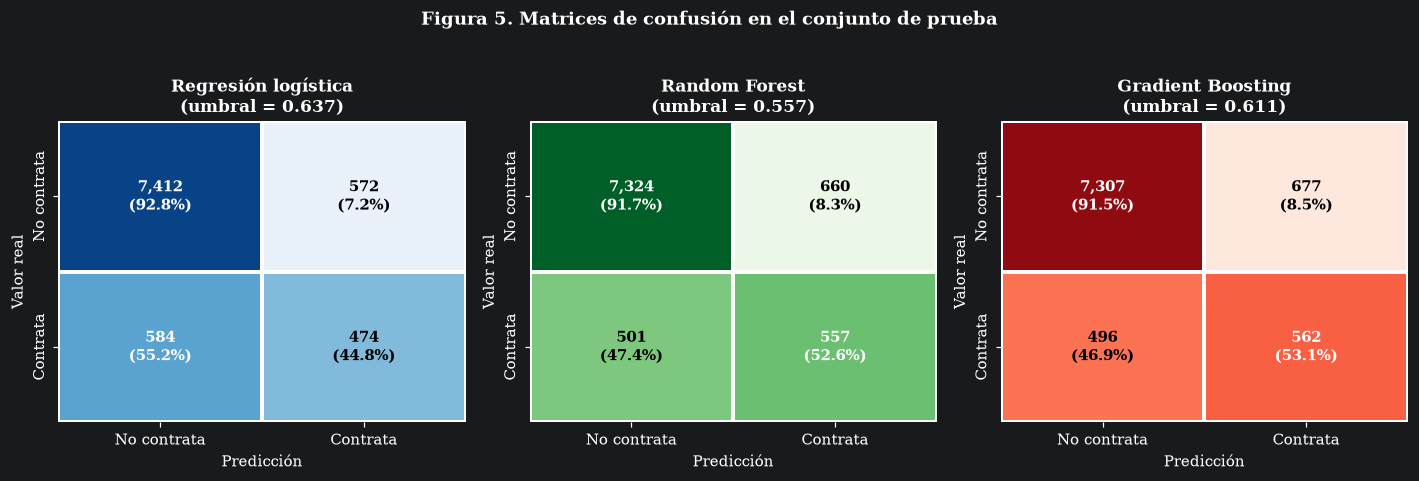

,VP,FP,FN,VN,Clientes contactados,% Base contactada,Lift vs. azar
Modelo,,,,,,,
Regresión logística,474,572,584,7412,1046,11.57,3.87
Random Forest,557,660,501,7324,1217,13.46,3.91
Gradient Boosting,562,677,496,7307,1239,13.70,3.88


In [34]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
filas = []
for ax, m in zip(axs, modelos):
    r = M[m]; pred = (r['p_te'] >= r['umbral']).astype(int)
    cm = confusion_matrix(y_te, pred); cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, cmap=CMAP[m], vmin=0, vmax=1, cbar=False, ax=ax, linewidths=1.5, linecolor='white')
    for i in range(2):
        for j in range(2):
            ax.text(j + .5, i + .5, f'{cm[i, j]:,}\n({cmn[i, j]:.1%})', ha='center', va='center', fontsize=10,
                    color='white' if cmn[i, j] > 0.5 else 'black', fontweight='bold')
    ax.set_xticklabels(['No contrata', 'Contrata']); ax.set_yticklabels(['No contrata', 'Contrata'], rotation=90, va='center')
    ax.set_xlabel('Predicción'); ax.set_ylabel('Valor real'); ax.grid(False)
    ax.set_title(f'{m}\n(umbral = {r["umbral"]:.3f})')
    tn, fp, fn, tp = cm.ravel()
    filas.append({'Modelo': m, 'VP': tp, 'FP': fp, 'FN': fn, 'VN': tn, 'Clientes contactados': tp + fp,
                  '% Base contactada': (tp + fp) / len(y_te) * 100, 'Lift vs. azar': (tp / (tp + fp)) / y_te.mean()})
fig.suptitle('Figura 5. Matrices de confusión en el conjunto de prueba', y=1.03, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig05_matrices_confusion')

tab_conf = pd.DataFrame(filas).set_index('Modelo')
display(tab_conf.round(2))
tab_conf.to_csv(f'{FIG_DIR}/tabla_confusion.csv')


## 4.3 Curvas ROC y Precision–Recall

El marcador grande de cada curva es el **punto de operación** (el umbral elegido). Las curvas Precision–Recall son las más informativas con desbalance: la línea de "azar" es la tasa de positivos (≈ 0,12), no 0,5.

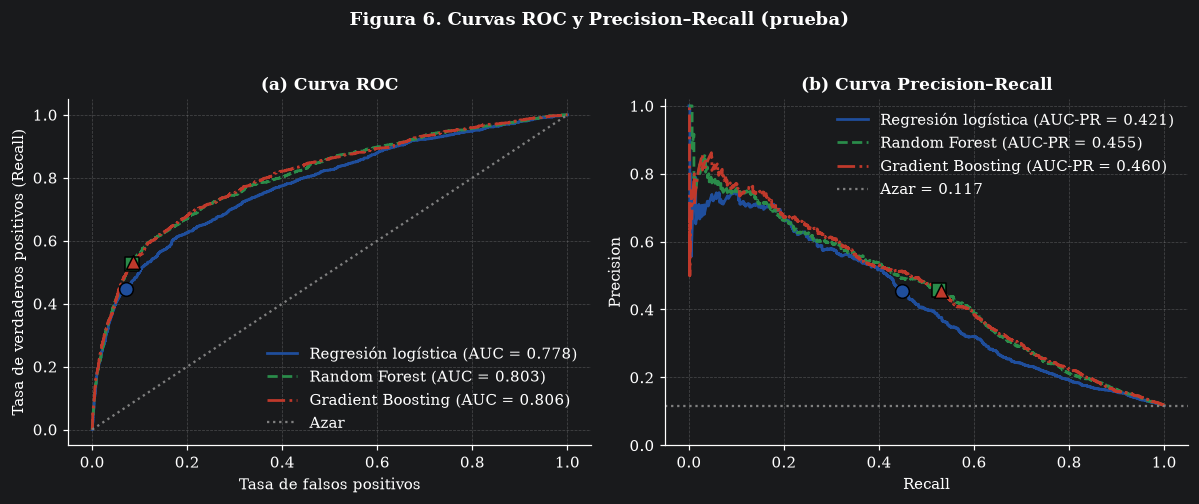

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for m in modelos:
    r = M[m]; p = r['p_te']; mo = r['m_opt']
    fpr, tpr, _ = roc_curve(y_te, p); pr, rc, _ = precision_recall_curve(y_te, p)
    ax[0].plot(fpr, tpr, color=COL[m], ls=LS[m], lw=1.8, label=f'{m} (AUC = {mo["AUC_ROC"]:.3f})')
    ax[1].plot(rc, pr, color=COL[m], ls=LS[m], lw=1.8, label=f'{m} (AUC-PR = {mo["AUC_PR"]:.3f})')
    fp, tn = tab_conf.loc[m, 'FP'], tab_conf.loc[m, 'VN']
    ax[0].scatter(fp / (fp + tn), mo['Recall'], marker=MK[m], s=80, color=COL[m], edgecolor='black', zorder=5)
    ax[1].scatter(mo['Recall'], mo['Precision'], marker=MK[m], s=80, color=COL[m], edgecolor='black', zorder=5)
ax[0].plot([0, 1], [0, 1], color='gray', ls=':', label='Azar')
ax[0].set_xlabel('Tasa de falsos positivos'); ax[0].set_ylabel('Tasa de verdaderos positivos (Recall)')
ax[0].set_title('(a) Curva ROC'); ax[0].legend(loc='lower right')
ax[1].axhline(y_te.mean(), color='gray', ls=':', label=f'Azar = {y_te.mean():.3f}')
ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_ylim(0, 1.02)
ax[1].set_title('(b) Curva Precision–Recall'); ax[1].legend(loc='upper right')
fig.suptitle('Figura 6. Curvas ROC y Precision–Recall (prueba)', y=1.03, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig06_curvas_roc_pr')


## 4.4 Efecto de la optimización de hiperparámetros (línea base vs. optimizado)

El AUC-PR no depende del umbral, por lo que mide el efecto **puro** del ajuste de hiperparámetros. El F1 sí depende del umbral: la línea base usa 0,5 y la versión optimizada usa el umbral óptimo, así que su mejora combina ambos efectos.

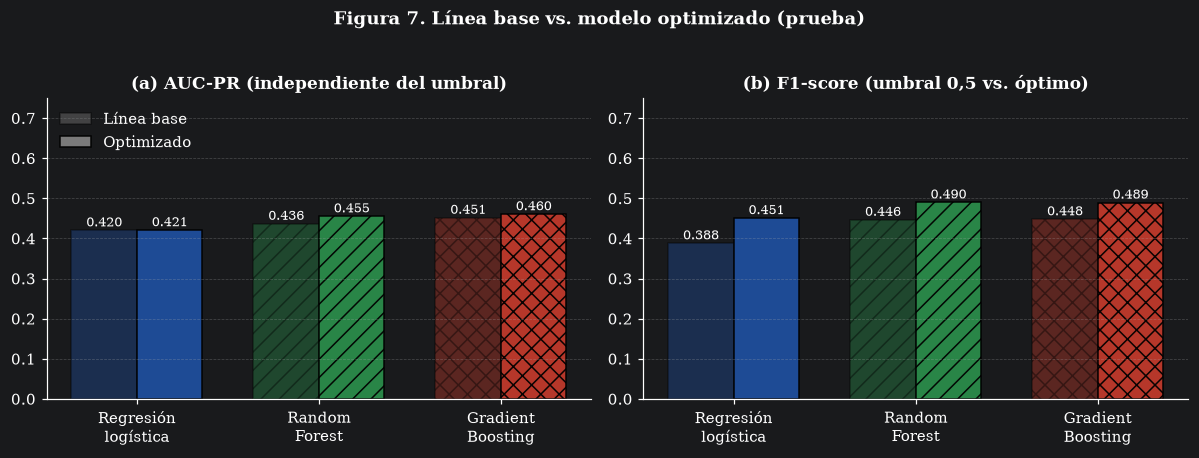

In [36]:
from matplotlib.patches import Patch
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(modelos)); w = 0.36
for a, met, tit in zip(ax, ['AUC_PR', 'F1'], ['(a) AUC-PR (independiente del umbral)', '(b) F1-score (umbral 0,5 vs. óptimo)']):
    for i, m in enumerate(modelos):
        vb, vo = M[m]['m_base'][met], M[m]['m_opt'][met]
        a.bar(i - w/2, vb, w, color=COL[m], alpha=0.40, edgecolor='black', hatch=HATCH[m])
        a.bar(i + w/2, vo, w, color=COL[m], alpha=0.95, edgecolor='black', hatch=HATCH[m])
        a.text(i - w/2, vb + 0.01, f'{vb:.3f}', ha='center', fontsize=8.5); a.text(i + w/2, vo + 0.01, f'{vo:.3f}', ha='center', fontsize=8.5)
    a.set_xticks(x); a.set_xticklabels([m.replace(' ', '\n') for m in modelos]); a.set_ylim(0, 0.75)
    a.set_title(tit); a.grid(axis='x', visible=False)
ax[0].legend(handles=[Patch(facecolor='gray', alpha=0.40, edgecolor='black', label='Línea base'),
                      Patch(facecolor='gray', alpha=0.95, edgecolor='black', label='Optimizado')], loc='upper left')
fig.suptitle('Figura 7. Línea base vs. modelo optimizado (prueba)', y=1.03, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig07_base_vs_optimizado')

## 4.5 Incertidumbre de las métricas (bootstrap pareado)

Con 9 042 clientes de prueba y ≈ 1 058 positivos, una diferencia pequeña entre modelos puede ser ruido. Se remuestrea el conjunto de prueba con reemplazo (500 réplicas) usando **los mismos índices para los tres modelos** (remuestreo *pareado*) y se obtienen intervalos de confianza del 95 % para AUC-PR y F1. Los modelos **no se reentrenan**: solo cambia la muestra de evaluación.

,AUC_PR,AUC_PR IC95 inf,AUC_PR IC95 sup,F1,F1 IC95 inf,F1 IC95 sup
Modelo,,,,,,
Regresión logística,0.4205,0.3911,0.4525,0.4506,0.4252,0.4759
Random Forest,0.4550,0.4239,0.4867,0.4897,0.4642,0.5131
Gradient Boosting,0.4603,0.4282,0.4928,0.4893,0.4646,0.5126


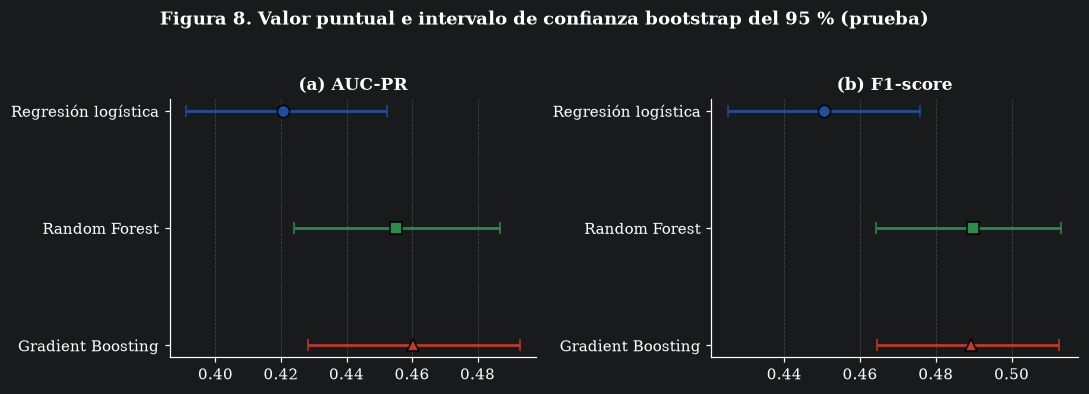

In [37]:
rng = np.random.default_rng(SEED)
yt = y_te.to_numpy(); n = len(yt); B = 500
P = {m: M[m]['p_te'] for m in modelos}; U = {m: M[m]['umbral'] for m in modelos}
boot = {m: {'AUC_PR': [], 'F1': []} for m in modelos}
for _ in range(B):
    ii = rng.integers(0, n, n); yy = yt[ii]
    for m in modelos:
        p = P[m][ii]
        boot[m]['AUC_PR'].append(average_precision_score(yy, p))
        boot[m]['F1'].append(f1_score(yy, (p >= U[m]).astype(int)))
boot = {m: {k: np.array(v) for k, v in d.items()} for m, d in boot.items()}

filas = []
for m in modelos:
    fila = {'Modelo': m}
    for met in ['AUC_PR', 'F1']:
        lo, hi = np.percentile(boot[m][met], [2.5, 97.5])
        fila[met] = M[m]['m_opt'][met]; fila[f'{met} IC95 inf'] = lo; fila[f'{met} IC95 sup'] = hi
    filas.append(fila)
tab_ic = pd.DataFrame(filas).set_index('Modelo')
display(tab_ic.round(4)); tab_ic.to_csv(f'{FIG_DIR}/tabla_intervalos_confianza.csv')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a, met, tit in zip(ax, ['AUC_PR', 'F1'], ['(a) AUC-PR', '(b) F1-score']):
    for i, m in enumerate(modelos):
        pt = M[m]['m_opt'][met]; lo, hi = np.percentile(boot[m][met], [2.5, 97.5])
        a.errorbar(pt, i, xerr=[[max(pt - lo, 0)], [max(hi - pt, 0)]], fmt=MK[m], color=COL[m], capsize=4, ms=8, mec='black', lw=1.8)
    a.set_yticks(range(len(modelos))); a.set_yticklabels(modelos); a.invert_yaxis(); a.set_title(tit); a.grid(axis='y', visible=False)
fig.suptitle('Figura 8. Valor puntual e intervalo de confianza bootstrap del 95 % (prueba)', y=1.04, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig08_intervalos_confianza')

## 4.6 Selección del mejor modelo y análisis de significancia

**Criterio de decisión:** Se selecciona el modelo con el mayor **AUC-PR en validación cruzada** (estimado exclusivamente con datos de entrenamiento). Posteriormente, se comprueba su consistencia en prueba y, mediante el bootstrap pareado, se verifica si la diferencia frente a los modelos competidores supera el ruido muestral (intervalo de confianza al 95 % que excluye el cero).


In [38]:
mejor = max(modelos, key=lambda m: M[m]['cv_score'])
mejor_test = max(modelos, key=lambda m: M[m]['m_opt']['AUC_PR'])

# Tabla ejecutiva de selección: sintetiza criterio CV, prueba, brecha, significancia y tiempo sin repetir métricas de tab_test
filas_sel = []
filas_dif = []
for m in modelos:
    if m == mejor:
        dif_txt = 'Referencia (Líder)'
        sig_txt = '—'
    else:
        d = boot[mejor]['AUC_PR'] - boot[m]['AUC_PR']; lo, hi = np.percentile(d, [2.5, 97.5])
        delta = M[mejor]['m_opt']['AUC_PR'] - M[m]['m_opt']['AUC_PR']
        dif_txt = f'+{delta:.4f} [{lo:+.4f}, {hi:+.4f}]'
        sig_txt = 'Sí' if (lo > 0 or hi < 0) else 'No (IC incluye 0)'
        filas_dif.append({'Comparación': f'{mejor} − {m}', 'Δ AUC-PR (prueba)': delta,
                          'IC95 inf': lo, 'IC95 sup': hi, 'Diferencia significativa': sig_txt})

    filas_sel.append({
        'Modelo': m,
        'AUC-PR valid. (CV)': M[m]['cv_score'],
        'AUC-PR prueba': M[m]['m_opt']['AUC_PR'],
        'Brecha CV-Prueba': M[m]['cv_score'] - M[m]['m_opt']['AUC_PR'],
        'Δ AUC-PR vs. Mejor (IC95)': dif_txt,
        'Diferencia significativa': sig_txt,
        'Tiempo entren. (s)': M[m]['segundos']
    })

tab_seleccion = pd.DataFrame(filas_sel).set_index('Modelo')
tab_dif = pd.DataFrame(filas_dif).set_index('Comparación')

print('Tabla ejecutiva de selección del mejor modelo:')
display(tab_seleccion.style.format({
    'AUC-PR valid. (CV)': '{:.4f}',
    'AUC-PR prueba': '{:.4f}',
    'Brecha CV-Prueba': '{:+.4f}',
    'Tiempo entren. (s)': '{:.1f}'
}))

tab_seleccion.to_csv(f'{FIG_DIR}/tabla_ranking_modelos.csv')
tab_dif.to_csv(f'{FIG_DIR}/tabla_diferencias.csv')

print(f'\n* Modelo seleccionado por validación cruzada : {mejor}')
print(f'* Modelo con mayor AUC-PR en prueba          : {mejor_test}  ->',
      'Coinciden (validación confirmada)' if mejor == mejor_test else 'Difieren')


Tabla ejecutiva de selección del mejor modelo:


,AUC-PR valid. (CV),AUC-PR prueba,Brecha CV-Prueba,Δ AUC-PR vs. Mejor (IC95),Diferencia significativa,Tiempo entren. (s)
Modelo,,,,,,
Regresión logística,0.4016,0.4205,-0.0189,"+0.0398 [+0.0246, +0.0548]",Sí,7.0
Random Forest,0.4349,0.4550,-0.0201,"+0.0053 [-0.0077, +0.0196]",No (IC incluye 0),121.1
Gradient Boosting,0.4411,0.4603,-0.0192,Referencia (Líder),—,68.0



* Modelo seleccionado por validación cruzada : Gradient Boosting
* Modelo con mayor AUC-PR en prueba          : Gradient Boosting  -> Coinciden (validación confirmada)


## 4.7 Diagnóstico del modelo seleccionado: importancia de variables y calibración

* **Importancia por permutación** (en prueba): cuánto cae el AUC-PR al barajar una variable. Es válida para cualquier modelo y evita el sesgo de la importancia por impureza.
* **Calibración:** como se usó `class_weight='balanced'`, las probabilidades salen **infladas** respecto de la tasa real. Esto no afecta al orden de los clientes (AUC) ni al umbral elegido, pero hay que saberlo si la probabilidad se interpreta como valor absoluto.

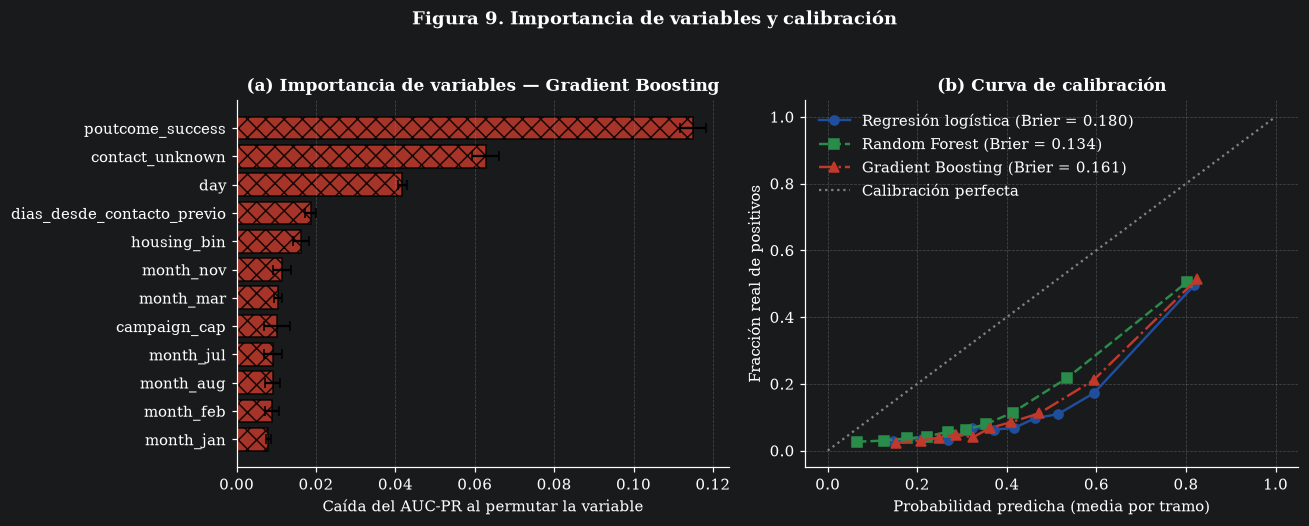

,Variable,Caída AUC-PR,Desv.
0,poutcome_success,0.1149,0.0033
1,contact_unknown,0.0627,0.0033
2,day,0.0418,0.0012
3,dias_desde_contacto_previo,0.0186,0.0015
4,housing_bin,0.0162,0.0020
5,month_nov,0.0115,0.0022
6,month_mar,0.0103,0.0010
7,campaign_cap,0.0102,0.0034
8,month_jul,0.0092,0.0022
9,month_aug,0.0090,0.0018


In [39]:
from sklearn.metrics import brier_score_loss
imp = permutation_importance(M[mejor]['pipe'], DATOS['A']['X_te'], y_te, scoring='average_precision',
                             n_repeats=5, random_state=SEED, n_jobs=-1)
tab_imp = (pd.DataFrame({'Variable': DATOS['A']['X_te'].columns, 'Caída AUC-PR': imp.importances_mean, 'Desv.': imp.importances_std})
           .sort_values('Caída AUC-PR', ascending=False).head(12).reset_index(drop=True))
tab_imp.to_csv(f'{FIG_DIR}/tabla_importancia_variables.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
t = tab_imp.iloc[::-1]
ax[0].barh(t['Variable'], t['Caída AUC-PR'], xerr=t['Desv.'], color=COL[mejor], edgecolor='black', hatch=HATCH[mejor], alpha=0.85, capsize=3)
ax[0].set_xlabel('Caída del AUC-PR al permutar la variable'); ax[0].set_title(f'(a) Importancia de variables — {mejor}')
ax[0].grid(axis='y', visible=False)

for m in modelos:
    pt_, pp_ = calibration_curve(y_te, P[m], n_bins=10, strategy='quantile')
    ax[1].plot(pp_, pt_, color=COL[m], ls=LS[m], marker=MK[m], lw=1.6, label=f'{m} (Brier = {brier_score_loss(y_te, P[m]):.3f})')
ax[1].plot([0, 1], [0, 1], color='gray', ls=':', label='Calibración perfecta')
ax[1].set_xlabel('Probabilidad predicha (media por tramo)'); ax[1].set_ylabel('Fracción real de positivos')
ax[1].set_title('(b) Curva de calibración'); ax[1].legend(loc='upper left')
fig.suptitle('Figura 9. Importancia de variables y calibración', y=1.03, fontweight='bold')
fig.tight_layout(); guardar(fig, 'fig09_importancia_calibracion')
display(tab_imp.round(4))

## 4.8 Respuestas a las preguntas guía

**1. ¿Qué tipo de problema se está resolviendo y qué técnica de modelado es la más adecuada?**
Es un problema de **clasificación supervisada binaria** para predecir la contratación de un depósito a plazo (`yb` ∈ {0, 1}). Dado el desbalance de clases (≈ 11.7 % de positivos), la técnica más adecuada es un ensamble no lineal con manejo de pesos por clase: **Gradient Boosting**, que demostró capturar las interacciones complejas de los datos superando a la regresión logística y con mayor estabilidad que Random Forest.

**2. ¿Cómo se dividirán y validarán los datos para probar el modelo de manera justa?**
* **Partición 80/20 estratificada** (`random_state=42`) realizada una sola vez sobre los índices, compartida idénticamente por todos los modelos (Sección 1.5).
* **Conjunto de prueba ciego**: reservado estrictamente para la evaluación final en la Sección 4, sin intervenir en el entrenamiento ni en la selección de hiperparámetros.
* **Validación cruzada estratificada (3 folds)** dentro del 80 % de entrenamiento para sintonizar hiperparámetros con métrica AUC-PR.
* **Calibración del umbral libre de fuga**: determinado mediante predicciones *out-of-fold* exclusivamente en entrenamiento.
* **Intervalos bootstrap pareados (500 réplicas)** en prueba para verificar si las diferencias entre modelos superan el ruido muestral.

**3. ¿Qué modelos candidatos se van a entrenar y comparar?**
Se compararon tres familias representativas:
1. **Regresión logística** (lineal interpretable con regularización L2 y estandarización).
2. **Random Forest** (ensamble *bagging* con submuestreo de variables y balanceo de pesos).
3. **Gradient Boosting** (ensamble aditivo secuencial con árboles someros, parada temprana y pesos de muestra).

De cada uno se evaluó su línea base y su versión optimizada mediante `RandomizedSearchCV`.

**4. ¿Qué métricas se usarán para evaluar el desempeño del modelo?**
Métricas de clasificación orientadas a datos desbalanceados: **AUC-PR** (métrica principal de selección), **F1-score**, **Recall**, **Precision**, **AUC-ROC**, **Balanced Accuracy**, **MCC** y **Matriz de confusión** traducida a métricas de impacto comercial (clientes contactados y Lift). Se descartan métricas de regresión y no supervisadas (Sección 4.0).

**5. ¿Cuál modelo se selecciona como mejor y por qué?**
Se selecciona **Gradient Boosting**. El resumen cuantitativo y la justificación detallada se presentan a continuación.

In [40]:
r = M[mejor]; mo = r['m_opt']; c = tab_conf.loc[mejor]
otros = [m for m in modelos if m != mejor]

print(f'MODELO SELECCIONADO: {mejor}\n')
print(f'* Mayor AUC-PR en validación cruzada ({r["cv_score"]:.4f}); en prueba confirma con AUC-PR {mo["AUC_PR"]:.4f} y AUC-ROC {mo["AUC_ROC"]:.4f}.')
print(f'* Con el umbral calibrado en train ({r["umbral"]:.3f}): F1 {mo["F1"]:.3f}, Recall {mo["Recall"]:.3f}, Precision {mo["Precision"]:.3f}, MCC {mo["MCC"]:.3f}.')
print(f'* Impacto comercial: contactando a {int(c["Clientes contactados"]):,} de {len(y_te):,} clientes ({c["% Base contactada"]:.1f} % del total) ' 
      f'se captura el {mo["Recall"]*100:.1f} % de los compradores reales; {mo["Precision"]*100:.1f} % de los contactados contrata ({c["Lift vs. azar"]:.1f} veces más que al azar).')
print(f'* Capacidad de generalización: brecha entrenamiento-validación {tab_gap.loc[mejor, "Brecha entren.-valid."]:+.4f} ' 
      f'y validación-prueba {tab_gap.loc[mejor, "Brecha valid.-prueba"]:+.4f} (AUC-PR).')

for m in otros:
    dif_info = tab_seleccion.loc[m, 'Δ AUC-PR vs. Mejor (IC95)']
    sig_info = tab_seleccion.loc[m, 'Diferencia significativa']
    print(f'* Frente a {m}: diferencia {dif_info} -> diferencia significativa: {sig_info}.')

print(f'* Mejora frente a su línea base: AUC-PR {M[mejor]["m_base"]["AUC_PR"]:.4f} -> {mo["AUC_PR"]:.4f}.')
print('\nLimitaciones prácticas: las probabilidades no están calibradas de forma absoluta debido a la ponderación de clases; '
      'para optimizar presupuestos comerciales exactos, se debe ajustar el umbral según la matriz de costos de llamada vs. beneficio por venta.')
print('\nArchivos generados en', FIG_DIR + ':'); print(*sorted(os.listdir(FIG_DIR)), sep='\n  ')


MODELO SELECCIONADO: Gradient Boosting

* Mayor AUC-PR en validación cruzada (0.4411); en prueba confirma con AUC-PR 0.4603 y AUC-ROC 0.8059.
* Con el umbral calibrado en train (0.611): F1 0.489, Recall 0.531, Precision 0.454, MCC 0.417.
* Impacto comercial: contactando a 1,239 de 9,042 clientes (13.7 % del total) se captura el 53.1 % de los compradores reales; 45.4 % de los contactados contrata (3.9 veces más que al azar).
* Capacidad de generalización: brecha entrenamiento-validación +0.0611 y validación-prueba -0.0192 (AUC-PR).
* Frente a Regresión logística: diferencia +0.0398 [+0.0246, +0.0548] -> diferencia significativa: Sí.
* Frente a Random Forest: diferencia +0.0053 [-0.0077, +0.0196] -> diferencia significativa: No (IC incluye 0).
* Mejora frente a su línea base: AUC-PR 0.4515 -> 0.4603.

Limitaciones prácticas: las probabilidades no están calibradas de forma absoluta debido a la ponderación de clases; para optimizar presupuestos comerciales exactos, se debe ajustar el umbra